# Air Quality Prediction — CO Concentration Regression

Individual university coursework project. The notebook displays outputs from an earlier execution; they have **not** been rerun after packaging.

Download `AirQualityUCI.xlsx` from the UCI Air Quality dataset and place it in `data/` before running all cells.

The original workflow includes interpolation by forward/backward filling before a random train/test split; read the limitations in the repository README when interpreting the saved metrics.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Load the Excel file
df = pd.read_excel("data/AirQualityUCI.xlsx")

# Display basic information
print("Dataset Shape:", df.shape)
print("\nFirst rows:")
df.head()

Dataset Shape: (9357, 15)

First rows:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360.00,150,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
1,2004-03-10,19:00:00,2.0,1292.25,112,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2,2004-03-10,20:00:00,2.2,1402.00,88,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
3,2004-03-10,21:00:00,2.2,1375.50,80,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
4,2004-03-10,22:00:00,1.6,1272.25,51,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


In [ ]:
# Check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   datetime64[ns]
 1   Time           9357 non-null   object        
 2   CO(GT)         9357 non-null   float64       
 3   PT08.S1(CO)    9357 non-null   float64       
 4   NMHC(GT)       9357 non-null   int64         
 5   C6H6(GT)       9357 non-null   float64       
 6   PT08.S2(NMHC)  9357 non-null   float64       
 7   NOx(GT)        9357 non-null   float64       
 8   PT08.S3(NOx)   9357 non-null   float64       
 9   NO2(GT)        9357 non-null   float64       
 10  PT08.S4(NO2)   9357 non-null   float64       
 11  PT08.S5(O3)    9357 non-null   float64       
 12  T              9357 non-null   float64       
 13  RH             9357 non-null   float64       
 14  AH             9357 non-null   float64       
dtypes: datetime64[ns](1),

In [ ]:
print("\nBasic Statistics:")
df.describe()


Basic Statistics:


,Date,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,2004-09-21 04:30:05.193972480,-34.207524,1048.869652,-159.090093,1.865576,894.475963,168.604200,794.872333,58.135898,1391.363266,974.951534,9.776600,39.483611,-6.837604
min,2004-03-10 00:00:00,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,2004-06-16 00:00:00,0.600000,921.000000,-200.000000,4.004958,711.000000,50.000000,637.000000,53.000000,1184.750000,699.750000,10.950000,34.050000,0.692275
50%,2004-09-21 00:00:00,1.500000,1052.500000,-200.000000,7.886653,894.500000,141.000000,794.250000,96.000000,1445.500000,942.000000,17.200000,48.550000,0.976823
75%,2004-12-28 00:00:00,2.600000,1221.250000,-200.000000,13.636091,1104.750000,284.200000,960.250000,133.000000,1662.000000,1255.250000,24.075000,61.875000,1.296223
max,2005-04-04 00:00:00,11.900000,2039.750000,1189.000000,63.741476,2214.000000,1479.000000,2682.750000,339.700000,2775.000000,2522.750000,44.600000,88.725000,2.231036
std,NaN,77.657170,329.817015,139.789093,41.380154,342.315902,257.424561,321.977031,126.931428,467.192382,456.922728,43.203438,51.215645,38.976670


In [ ]:
# Replace -200 with NaN (these are missing value markers in this dataset)
df_cleaned = df.replace(-200, np.nan)

In [ ]:

# Combine Date and Time from ORIGINAL df since df_cleaned still has them

df_cleaned['DateTime'] = pd.to_datetime(
    df_cleaned['Date'].astype(str) + ' ' + df_cleaned['Time'].astype(str),
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
)
df_cleaned.set_index('DateTime', inplace=True)

# Now drop from df_cleaned (not from df)
df_cleaned.drop(['Date', 'Time'], axis=1, inplace=True, errors='ignore')

df_cleaned.head()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
DateTime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.00,150.0,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
2004-03-10 19:00:00,2.0,1292.25,112.0,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2004-03-10 20:00:00,2.2,1402.00,88.0,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
2004-03-10 21:00:00,2.2,1375.50,80.0,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
2004-03-10 22:00:00,1.6,1272.25,51.0,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


In [ ]:
#check missing data
missing_counts = df_cleaned.isnull().sum()
missing_percentages = (missing_counts / len(df_cleaned)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage': missing_percentages
})
print(missing_df[missing_df['Missing Count'] > 0])

               Missing Count  Percentage
CO(GT)                  1683   17.986534
PT08.S1(CO)              366    3.911510
NMHC(GT)                8443   90.231912
C6H6(GT)                 366    3.911510
PT08.S2(NMHC)            366    3.911510
NOx(GT)                 1639   17.516298
PT08.S3(NOx)             366    3.911510
NO2(GT)                 1642   17.548360
PT08.S4(NO2)             366    3.911510
PT08.S5(O3)              366    3.911510
T                        366    3.911510
RH                       366    3.911510
AH                       366    3.911510


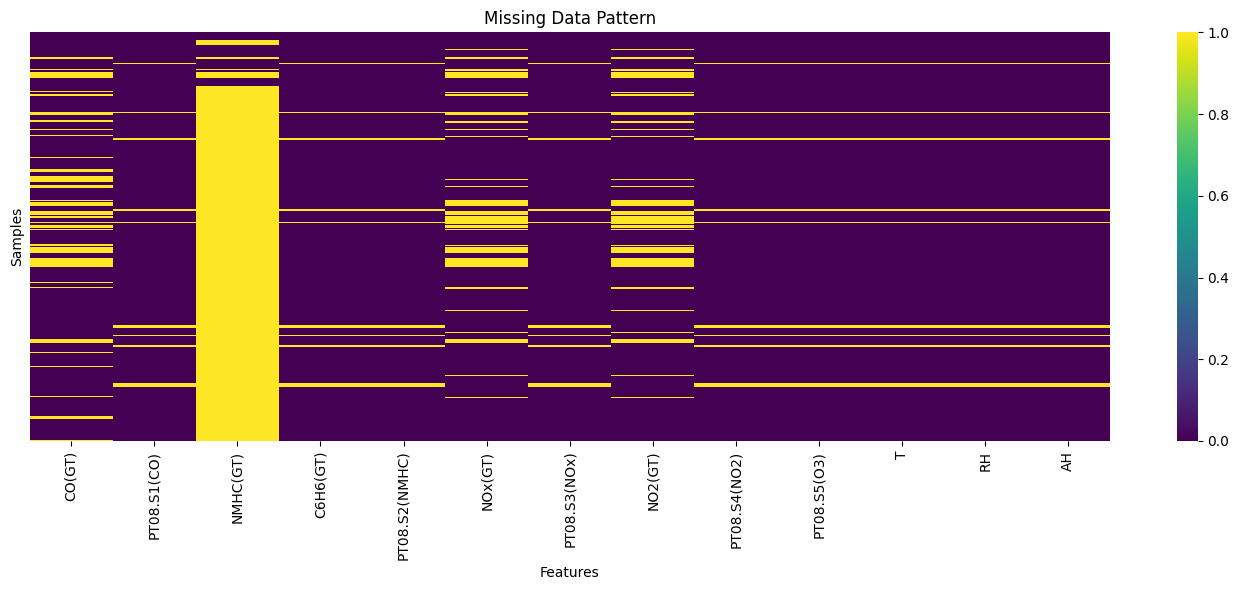

Missing data pattern saved to missing_data_pattern.png


In [ ]:
# Visualize missing data pattern
plt.figure(figsize=(14, 6))
sns.heatmap(df_cleaned.isnull(), cbar=True, yticklabels=False, cmap='viridis')
plt.title('Missing Data Pattern')
plt.xlabel('Features')
plt.ylabel('Samples')
plt.tight_layout()
plt.show()
print("Missing data pattern saved to missing_data_pattern.png")

In [ ]:
# Handle missing values using forward fill followed by backward fill
# Drop 'NMHC(GT)' because ~90% of its values are missing, making it unreliable for modeling
df_cleaned=df_cleaned.drop(columns='NMHC(GT)')
df_filled = df_cleaned.fillna(method='ffill').fillna(method='bfill')

# Verify no missing values remain
print("Missing values after filling:")
print(df_filled.isnull().sum().sum())

Missing values after filling:
0


/tmp/ipython-input-1184705156.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_filled = df_cleaned.fillna(method='ffill').fillna(method='bfill')


In [ ]:
# Check for duplicates
duplicates = df_filled.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

# Remove duplicates if any
df_no_duplicates = df_filled.drop_duplicates()
print(f"Shape after removing duplicates: {df_no_duplicates.shape}")

Number of duplicate rows: 32
Shape after removing duplicates: (9325, 12)


In [ ]:
# Extract temporal features


df_processed = df_no_duplicates.copy()
df_processed.index = pd.to_datetime(df_processed.index)

df_processed['Hour'] = df_processed.index.hour
df_processed['Month'] = df_processed.index.month
df_processed['DayOfWeek'] = df_processed.index.dayofweek


print("Temporal features added")
df_processed.head()

Temporal features added


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Hour,Month,DayOfWeek
DateTime,,,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.00,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754,18,3,2
2004-03-10 19:00:00,2.0,1292.25,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487,19,3,2
2004-03-10 20:00:00,2.2,1402.00,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239,20,3,2
2004-03-10 21:00:00,2.2,1375.50,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713,21,3,2
2004-03-10 22:00:00,1.6,1272.25,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794,22,3,2


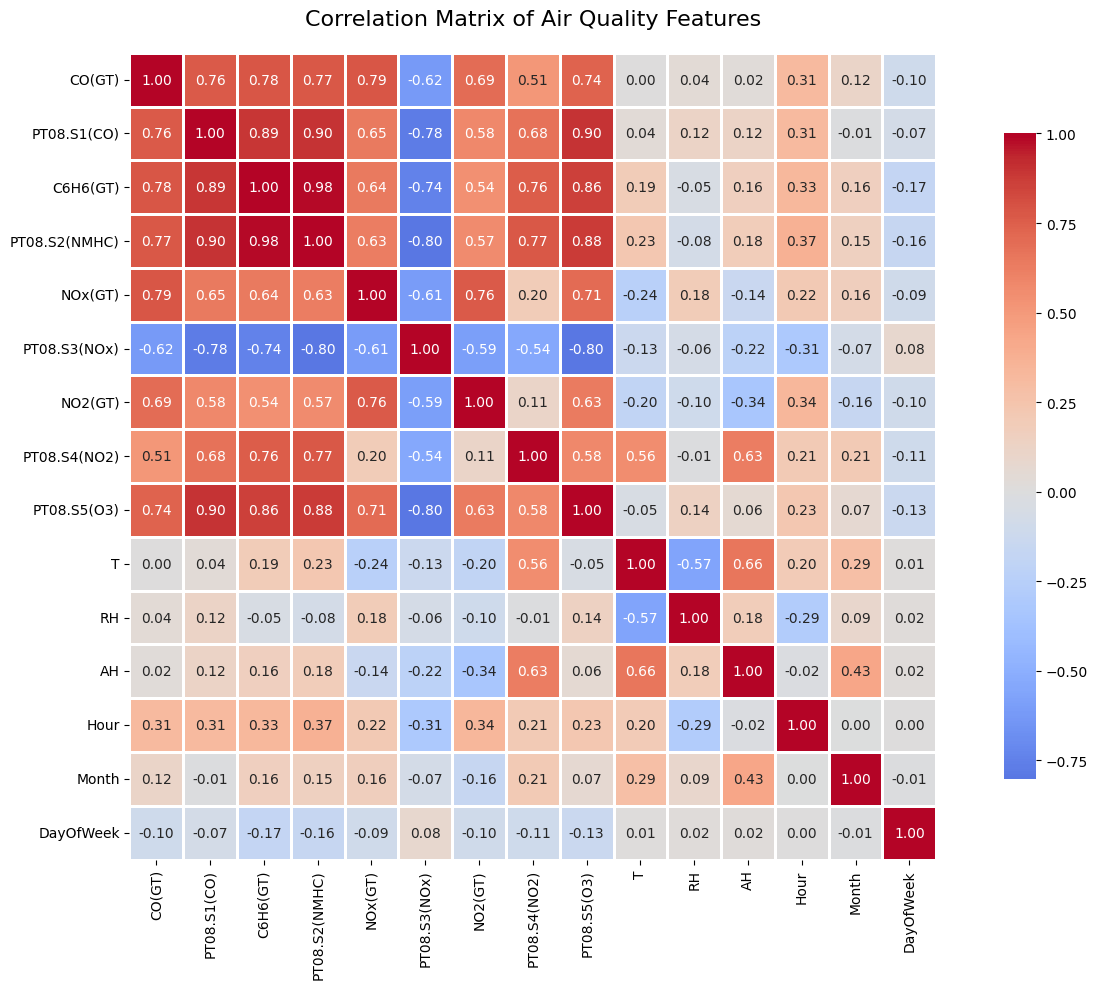

In [ ]:
# Calculate correlation matrix
correlation_matrix = df_processed.corr()

# Visualize correlation matrix
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Air Quality Features', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

In [ ]:
x = df_processed.drop(columns=['CO(GT)'])
y = df_processed['CO(GT)']
x



,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Hour,Month,DayOfWeek
DateTime,,,,,,,,,,,,,,
2004-03-10 18:00:00,1360.00,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.600,48.875001,0.757754,18,3,2
2004-03-10 19:00:00,1292.25,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.300,47.700000,0.725487,19,3,2
2004-03-10 20:00:00,1402.00,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.900,53.975000,0.750239,20,3,2
2004-03-10 21:00:00,1375.50,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.000,60.000000,0.786713,21,3,2
2004-03-10 22:00:00,1272.25,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.150,59.575001,0.788794,22,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2005-04-04 10:00:00,1314.25,13.529605,1101.25,471.7,538.50,189.8,1374.25,1728.50,21.850,29.250000,0.756824,10,4,0
2005-04-04 11:00:00,1162.50,11.355157,1027.00,353.3,603.75,179.2,1263.50,1269.00,24.325,23.725000,0.711864,11,4,0
2005-04-04 12:00:00,1142.00,12.374538,1062.50,293.0,603.25,174.7,1240.75,1092.00,26.900,18.350000,0.640649,12,4,0


In [ ]:
from sklearn.model_selection import train_test_split

# Assuming X = features, y = target (carbon concentration)
x_train, x_test, y_train, y_test = train_test_split(
    x, y,          # your features and target
    test_size=0.2, # 20% for testing, 80% for training
    random_state=42
)


In [ ]:
# Step 2: Now identify columns to normalize (on X_train only)
cols_to_normalize = x_train.select_dtypes(include=[np.number]).columns.tolist()
temporal_cols = ['Hour', 'DayOfWeek', 'Month']
cols_to_normalize = [col for col in cols_to_normalize if col not in temporal_cols]

print(f"Scaling these columns: {cols_to_normalize}")

# Step 3: Create scaled copies of train and test
scaler = StandardScaler()

# Fit scaler ONLY on training data
x_train_scaled = x_train.copy()
x_train_scaled[cols_to_normalize] = scaler.fit_transform(x_train[cols_to_normalize])

# Transform test data using training statistics
x_test_scaled = x_test.copy()
x_test_scaled[cols_to_normalize] = scaler.transform(x_test[cols_to_normalize])

Scaling these columns: ['PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Linear Regression baseline
lr = LinearRegression()
lr.fit(x_train_scaled, y_train)
lr_pred = lr.predict(x_test_scaled)
lr_r2 = r2_score(y_test, lr_pred)

# Random Forest baseline
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(x_train_scaled, y_train)
rf_pred = rf.predict(x_test_scaled)
rf_r2 = r2_score(y_test, rf_pred)

print(f"\nComparison of Baseline Models:")
print(f"Linear Regression R²: {lr_r2:.4f}")
print(f"Random Forest R²: {rf_r2:.4f}")


Comparison of Baseline Models:
Linear Regression R²: 0.8024
Random Forest R²: 0.9042


In [ ]:
# 2. Create BASELINE model with DEFAULT parameters
from  xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score


baseline_xgb = XGBRegressor(random_state=42, n_jobs=-1)
baseline_xgb.fit(x_train_scaled, y_train)

# 3. Evaluate baseline
baseline_pred = baseline_xgb.predict(x_test_scaled)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

print("="*50)
print("BASELINE MODEL (Default Parameters):")
print(f"MSE: {baseline_mse:.4f}")
print(f"R²: {baseline_r2:.4f}")
print("="*50)

BASELINE MODEL (Default Parameters):
MSE: 0.1868
R²: 0.9126


In [ ]:

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

xgb = XGBRegressor(random_state=42)
xgb_params={
        "n_estimators": [300, 500, 800],
        "max_depth": [4, 6, 10],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 3, 5]
    }

# Use RandomizedSearchCV instead of GridSearchCV
xgb_random = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_params,
    n_iter=20,  # number of random combinations to try
    cv=3,
    verbose=2,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    random_state=42
)

xgb_random.fit(x_train_scaled, y_train)

pred_xgb = xgb_random.predict(x_test_scaled)


print("Best XGBoost Params (Random Search):", xgb_random.best_params_)
print("XGBoost MSE:", mean_squared_error(y_test, pred_xgb))
print("XGBoost R2:", r2_score(y_test, pred_xgb))


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best XGBoost Params (Random Search): {'subsample': 0.8, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
XGBoost MSE: 0.1704983802176801
XGBoost R2: 0.9202202635203746


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from scipy.stats import uniform
import numpy as np
from scipy.stats import uniform


# Define the parameter distribution
param_dist = {
    'hidden_layer_sizes': [(64,32), (128,64)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'alpha': uniform(0.0001, 0.01),          # random regularization
    'learning_rate_init': uniform(0.001, 0.01) # random learning rates
}

mlp = MLPRegressor(max_iter=1000, random_state=42)  # reduced iterations for speed

# Randomized search: n_iter=20 → tests 20 random combinations
random_search = RandomizedSearchCV(
    mlp,
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

random_search.fit(x_train_scaled, y_train)

print("Best params:", random_search.best_params_)
print("Best CV score:", random_search.best_score_)

# Use the best estimator
best_mlp = random_search.best_estimator_
y_pred = best_mlp.predict(x_test_scaled)
print("MSE:", mean_squared_error(y_test, y_pred))
print("r squared",  r2_score(y_test, y_pred))

Best params: {'activation': 'tanh', 'alpha': np.float64(0.00975255307264138), 'hidden_layer_sizes': (128, 64), 'learning_rate_init': np.float64(0.006426960831582485), 'solver': 'adam'}
Best CV score: -0.2168777952410972
MSE: 0.20014829604204926
r squared 0.90634645153406
